# Pneumonia Detection from Dataset Exploration

This Notebook explores the chest X-ray dataset used to detect pneumonia

Dataset structure
- train/
- val/
- test/

Classes or Labels
- NORMAL
- PNEUMONIA

GOALS:
- Understand dataset structure
- Count images
- Check class balance

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import random

## Dataset Dir and Labels

In [93]:
train_dir = "./Dataset_Pneumonia/train"
val_dir = "./Dataset_Pneumonia/val"
test_dir = "./Dataset_Pneumonia/test"

print("Train Labels:", os.listdir(train_dir))
print("Validation Labels:", os.listdir(val_dir))
print("Test classes:", os.listdir(test_dir))


Train Labels: ['NORMAL', 'PNEUMONIA']
Validation Labels: ['NORMAL', 'PNEUMONIA']
Test classes: ['NORMAL', 'PNEUMONIA']


## Nbr of images per classes for each dir

In [94]:
def count_images(dir):
    total = 0
    for label in os.listdir(dir):
        path = os.path.join(dir, label)
        total += len(os.listdir(path))
    return total

print("Train images:", count_images(train_dir))
print("Validation images:", count_images(val_dir))
print("Test images:", count_images(test_dir))

Train images: 5216
Validation images: 16
Test images: 624


### Dataset size analysis

The count_images function reveal that the validations folder has 16 images, which is significantly smaller than the train set and test set.
This may limit the reliability of validation metrics during model training.

## Balance of each dir

In [95]:
def count_per_classes(dir):
    counts = {}
    for label in os.listdir(dir):
        path = os.path.join(dir, label)
        counts[label] = len(os.listdir(path))
    return counts
print("Train balance:", count_per_classes(train_dir))
print("Validation balance:", count_per_classes(val_dir))
print("Test balance:", count_per_classes(test_dir))


Train balance: {'NORMAL': 1341, 'PNEUMONIA': 3875}
Validation balance: {'NORMAL': 8, 'PNEUMONIA': 8}
Test balance: {'NORMAL': 234, 'PNEUMONIA': 390}


### Class Distribution Analysis

The train dir shows 1341 img normal and 3875 pneumonia, thus the dataset is imbalanced.
This can affect model performance and bias predictions toward the majority class.

### Visualization of the imbalanced

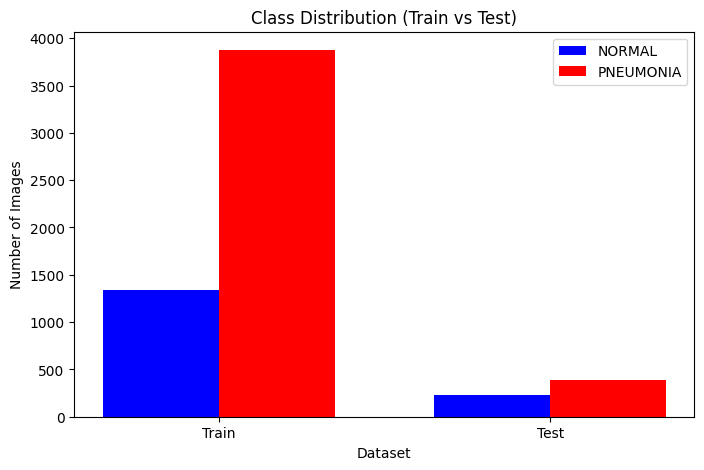

In [ ]:
def plot_train_test_balance():
    train_counts = count_per_classes(train_dir)
    test_counts = count_per_classes(test_dir)
    labels = ["Train", "Test"]
    normal_counts = [
        train_counts["NORMAL"],
        test_counts["NORMAL"]
    ]
    pneumonia_counts = [
        train_counts["PNEUMONIA"],
        test_counts["PNEUMONIA"]
    ]

    x = np.arange(len(labels))
    width = 0.35
    plt.figure(figsize=(16,8))

    plt.bar(x - width/2, normal_counts, width, label="NORMAL", color="blue")
    plt.bar(x + width/2, pneumonia_counts, width, label="PNEUMONIA", color="red")

    plt.xlabel("Dataset")
    plt.ylabel("Number of Images")
    plt.title("Class Distribution (Train vs Test)")
    plt.xticks(x, labels)
    plt.legend()
    plt.show()
    plt.close()
plot_train_test_balance()

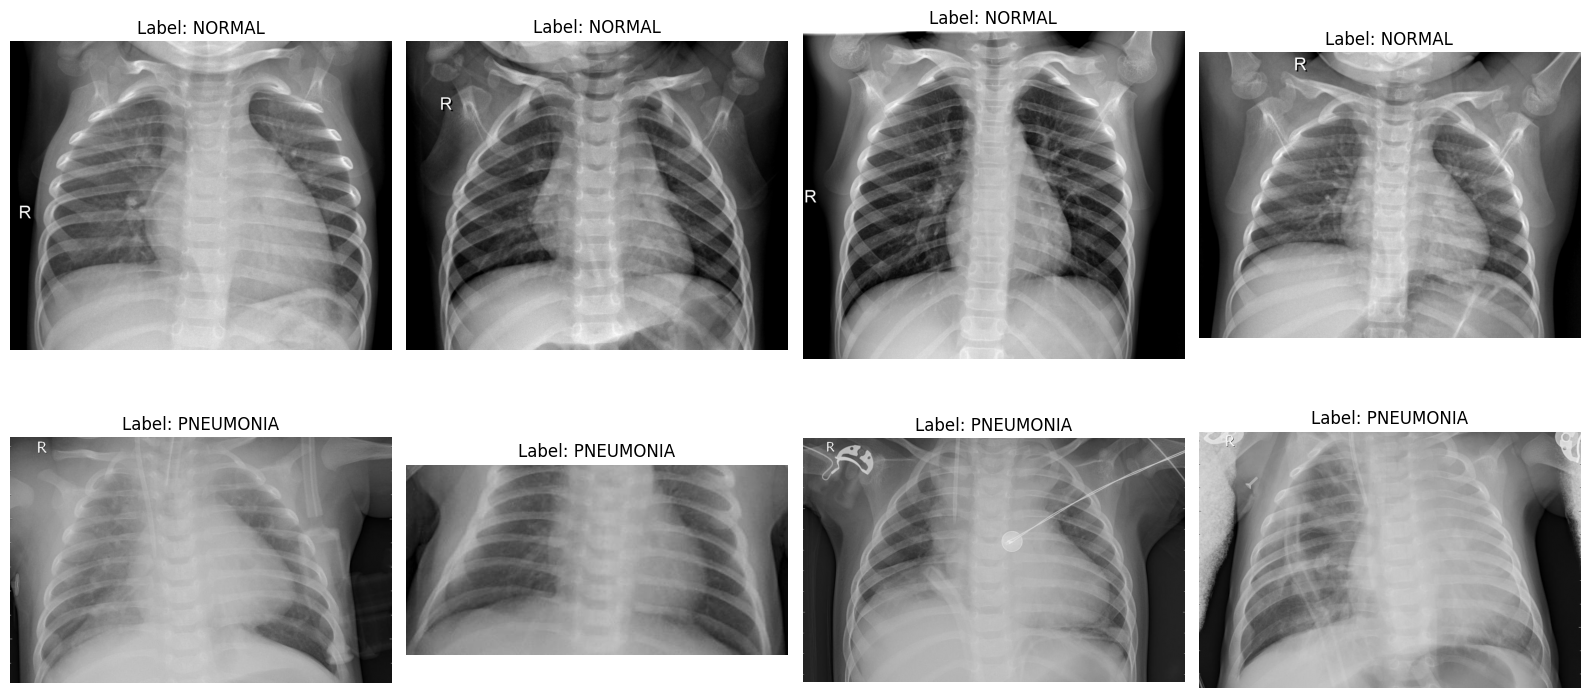

In [ ]:


def display_random_img(base_dir, labels=['NORMAL', 'PNEUMONIA'], n=4):
    plt.figure(figsize=(16, 8))
    for i, category in enumerate(labels):
        folder_path = os.path.join(base_dir, category)
        img_names = random.sample(os.listdir(folder_path), n)
        for j, img_name in enumerate(img_names):
            plt.subplot(len(labels), n, i * n + j + 1)
            img_path = os.path.join(folder_path, img_name)
            img = Image.open(img_path)
            plt.imshow(img, cmap='gray')
            plt.title(f"Label: {category}")
            plt.axis('off')
    plt.tight_layout()
    plt.show()

display_random_img(train_dir)